In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Optional
import plotly.express as px

In [7]:
df = pd.read_excel(r"D:\8218061-week2_EDA_python_advance-20260606T113023Z-3-001 (1)\week2_EDA_python_advance\sample - superstore (2).xlsx", sheet_name="Orders")

In [8]:
# Display first 10 rows
print(df.head(10))

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0    2718  CA-2016-100006 2016-09-07 2016-09-13  Standard Class    DK-13375   
1    6288  CA-2016-100090 2016-07-08 2016-07-12  Standard Class    EB-13705   
2    6289  CA-2016-100090 2016-07-08 2016-07-12  Standard Class    EB-13705   
3    9515  CA-2016-100293 2016-03-14 2016-03-18  Standard Class    NF-18475   
4    3084  CA-2016-100328 2016-01-28 2016-02-03  Standard Class    JC-15340   
5    3836  CA-2016-100363 2016-04-08 2016-04-15  Standard Class    JM-15655   
6    3837  CA-2016-100363 2016-04-08 2016-04-15  Standard Class    JM-15655   
7    9441  CA-2016-100391 2016-05-25 2016-05-29  Standard Class    BW-11065   
8    6569  CA-2016-100678 2016-04-18 2016-04-22  Standard Class    KM-16720   
9    6570  CA-2016-100678 2016-04-18 2016-04-22  Standard Class    KM-16720   

      Customer Name      Segment Country/Region           City  ...  \
0       Dennis Kane     Consumer  United States  New York C

In [9]:
# Shape
print("Shape:", df.shape)

Shape: (9994, 21)


In [10]:
# Column names
print("Columns:", df.columns.tolist())

Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [11]:
# Basic info (dtypes, non-null counts)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9994 non-null   int64         
 1   Order ID        9994 non-null   object        
 2   Order Date      9994 non-null   datetime64[ns]
 3   Ship Date       9994 non-null   datetime64[ns]
 4   Ship Mode       9994 non-null   object        
 5   Customer ID     9994 non-null   object        
 6   Customer Name   9994 non-null   object        
 7   Segment         9994 non-null   object        
 8   Country/Region  9994 non-null   object        
 9   City            9994 non-null   object        
 10  State           9994 non-null   object        
 11  Postal Code     9983 non-null   float64       
 12  Region          9994 non-null   object        
 13  Product ID      9994 non-null   object        
 14  Category        9994 non-null   object        
 15  Sub-

In [12]:
print(df.isnull().sum())
print(df.isnull().sum() / len(df) * 100)   # as %

Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State              0
Postal Code       11
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount           0
Profit             0
dtype: int64
Row ID            0.000000
Order ID          0.000000
Order Date        0.000000
Ship Date         0.000000
Ship Mode         0.000000
Customer ID       0.000000
Customer Name     0.000000
Segment           0.000000
Country/Region    0.000000
City              0.000000
State             0.000000
Postal Code       0.110066
Region            0.000000
Product ID        0.000000
Category          0.000000
Sub-Category      0.000000
Product Name      0.000000
Sales             0.000000
Quantity          0.000000
Discount          0.000000
Profit

In [14]:
# For numeric columns → fill with mean or median
df['Sales'].fillna(df['Sales'].mean(), inplace=True)

# Or just drop rows with nulls (if very few)
df.dropna(inplace=True)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_1900\428582587.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sales'].fillna(df['Sales'].mean(), inplace=True)


In [15]:
df.dtypes

# Convert date columns if they're strings
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date']  = pd.to_datetime(df['Ship Date'])

In [16]:
print("Duplicates:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

Duplicates: 0


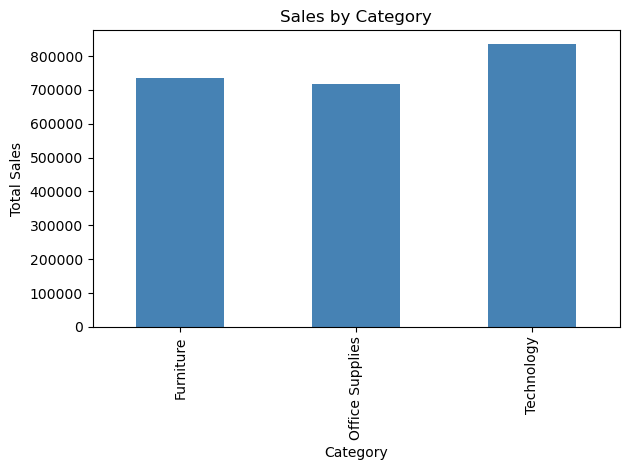

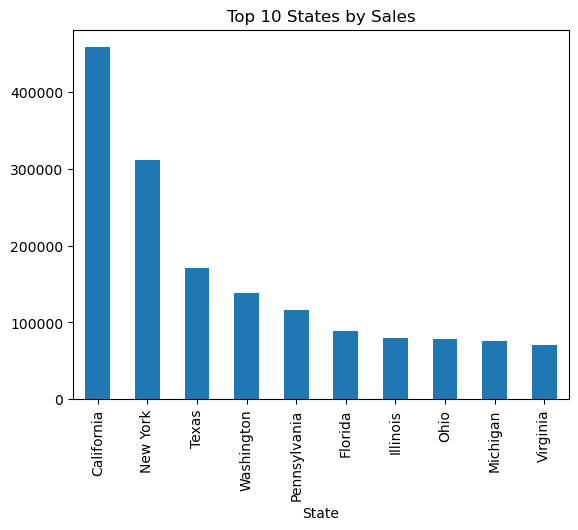

In [17]:
# Sales by Category
df.groupby('Category')['Sales'].sum().plot(kind='bar', title='Sales by Category', color='steelblue')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

# Repeat for: Sub-Category, Segment, Region, State (top 10 states)
top_states = df.groupby('State')['Sales'].sum().nlargest(10)
top_states.plot(kind='bar', title='Top 10 States by Sales')
plt.show()

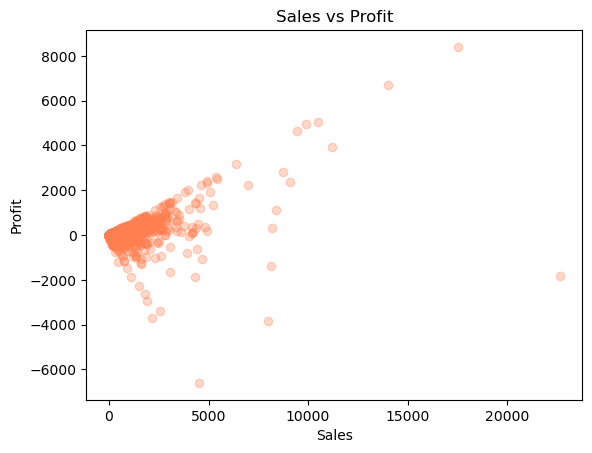

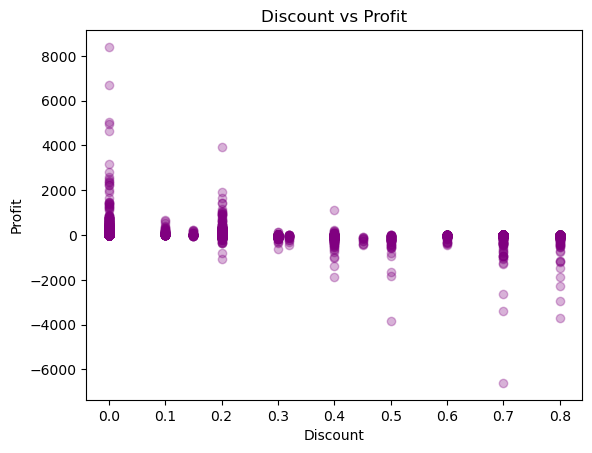

In [18]:
# Sales vs Profit
plt.scatter(df['Sales'], df['Profit'], alpha=0.3, color='coral')
plt.xlabel('Sales'); plt.ylabel('Profit')
plt.title('Sales vs Profit')
plt.show()

# Discount vs Profit
plt.scatter(df['Discount'], df['Profit'], alpha=0.3, color='purple')
plt.xlabel('Discount'); plt.ylabel('Profit')
plt.title('Discount vs Profit')
plt.show()

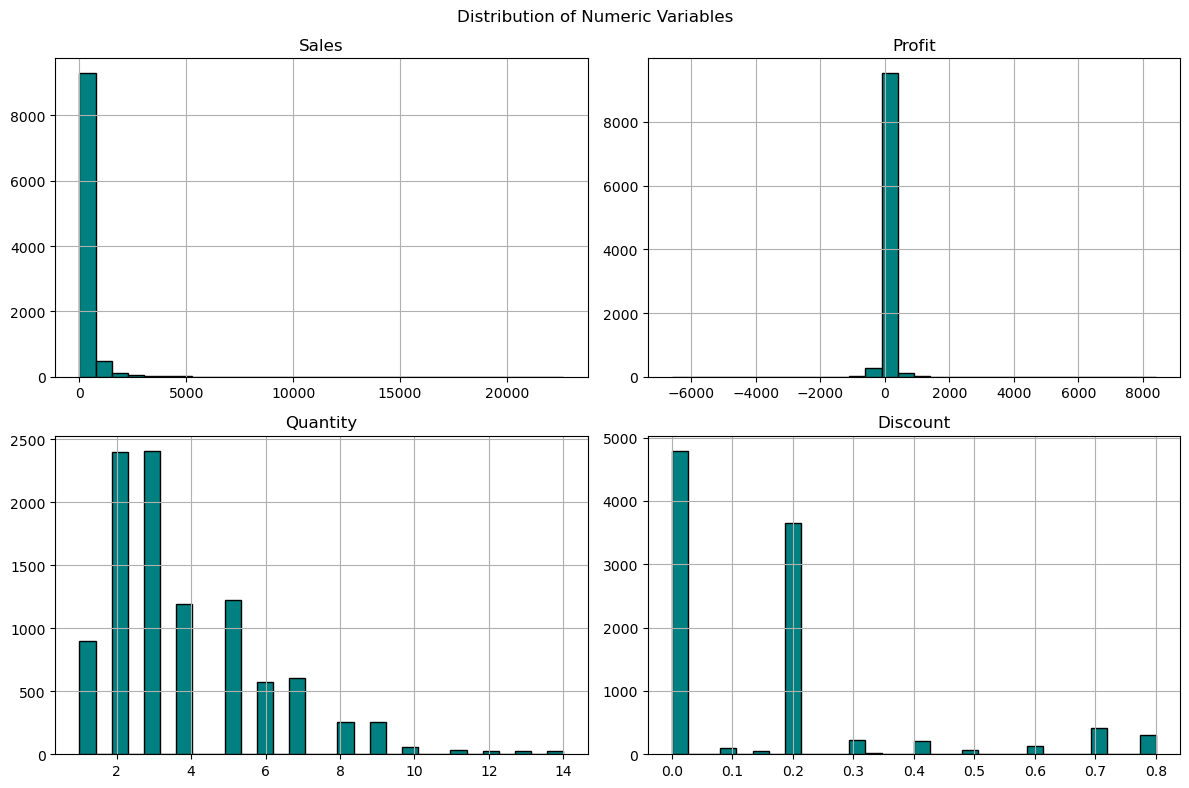

In [19]:
cols = ['Sales', 'Profit', 'Quantity', 'Discount']
df[cols].hist(bins=30, figsize=(12, 8), color='teal', edgecolor='black')
plt.suptitle('Distribution of Numeric Variables')
plt.tight_layout()
plt.show()

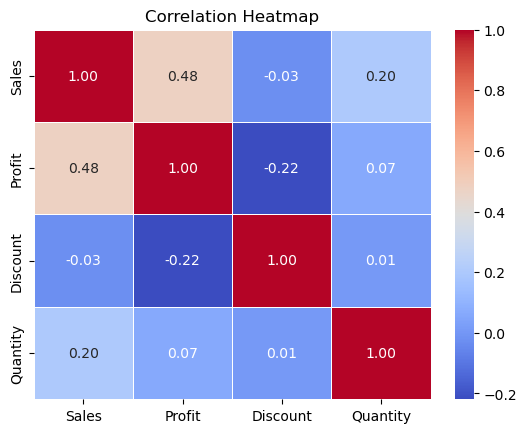

In [20]:
corr = df[['Sales', 'Profit', 'Discount', 'Quantity']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

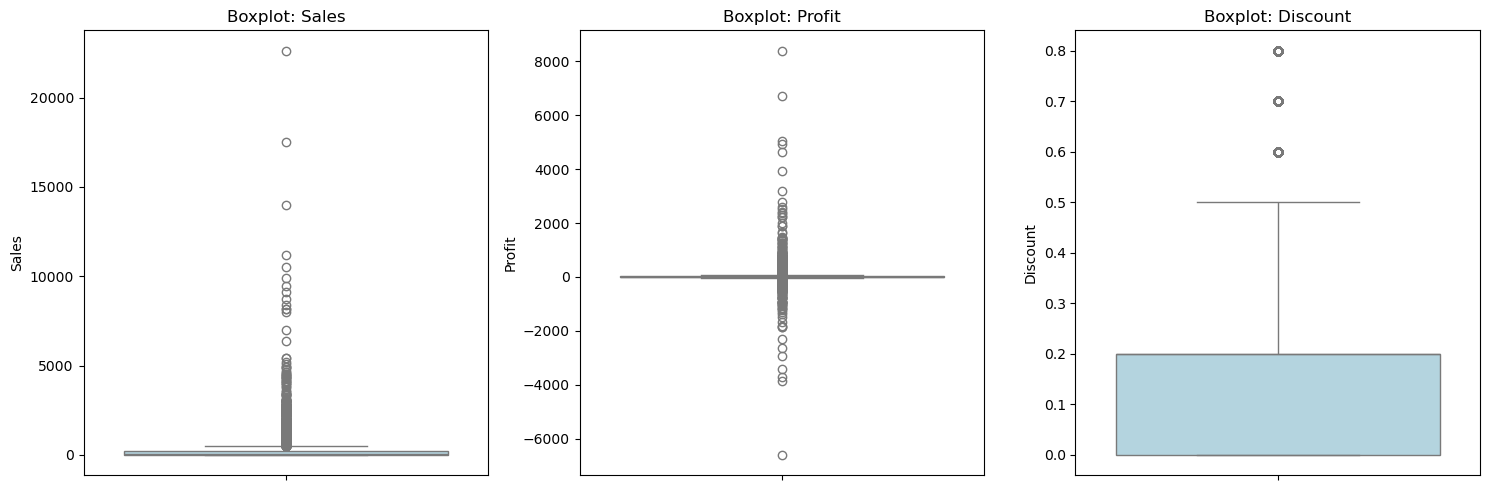

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ['Sales', 'Profit', 'Discount']):
    sns.boxplot(y=df[col], ax=ax, color='lightblue')
    ax.set_title(f'Boxplot: {col}')

plt.tight_layout()
plt.show()